In [1]:
import warnings
warnings.filterwarnings("ignore", category=Warning)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split

In [5]:
df = pd.read_csv("preprocessed_songs.csv")
df.head()

,Unnamed: 0,artist,track,listeners,playcount,tags,plct/lstn,Disco,Grunge,Hip-Hop,...,pop rock,punk,rap,rnb,rock,shoegaze,soft rock,soul,synthpop,trap
0,0,Harry Styles,Aperture,524766,4295814,"['House', 'electronic', 'alternative', 'Disco']",8.186152,1,0,0,...,0,0,0,0,0,0,0,0,0,0
1,1,Addison Rae,Fame Is a Gun,959674,17809028,"['electropop', 'pop', 'synthpop', 'dance-pop']",18.557373,0,0,0,...,0,0,0,0,0,0,0,0,1,0
2,3,Zara Larsson,Midnight Sun,620819,10022037,['pop'],16.143251,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,Dominic Fike,Babydoll,1425059,21116521,"['alternative', 'indie', 'pop']",14.817998,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,5,Djo,End of Beginning,1946092,32806375,"['indie', 'pop', 'indie pop', 'rock']",16.857566,0,0,0,...,0,0,0,0,1,0,0,0,0,0


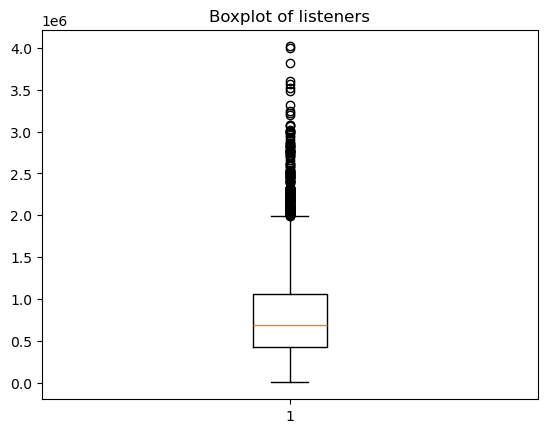

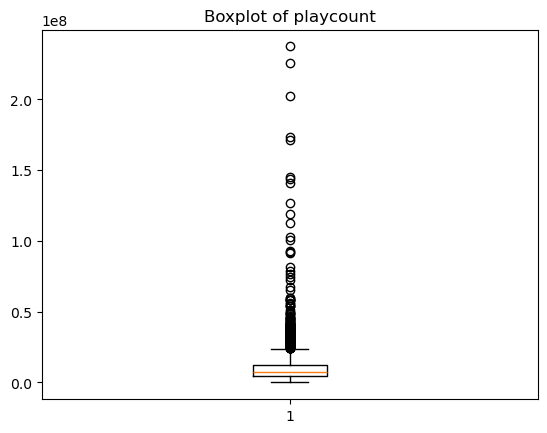

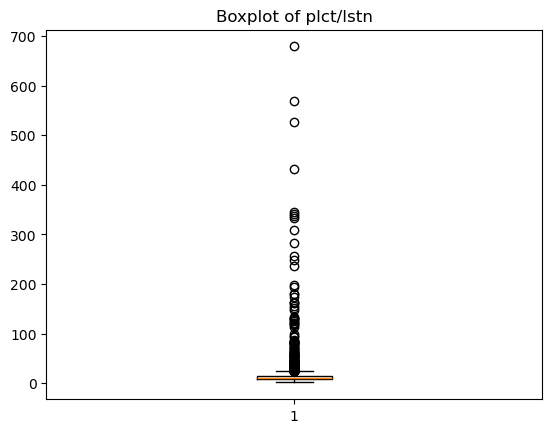

In [27]:
#Data Exploration and Visualization
plt.figure()
plt.boxplot(df["listeners"])
plt.title("Boxplot of " +  "listeners")
plt.show()

plt.figure()
plt.boxplot(df["playcount"])
plt.title("Boxplot of " +  "playcount")
plt.show()


plt.figure()
plt.boxplot(df["plct/lstn"])
plt.title("Boxplot of " +  "plct/lstn")
plt.show()

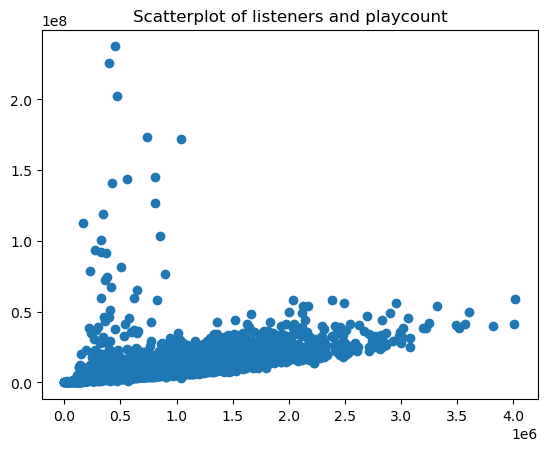

In [23]:
#Scatterplot
plt.figure()
plt.scatter(df["listeners"],df["playcount"])
plt.title("Scatterplot of " +  "listeners" + " and " +"playcount")
plt.show()

In [29]:
#Correlation 
correlation_value = df['playcount'].corr(df['listeners'])
correlation_value

0.48846603324350524

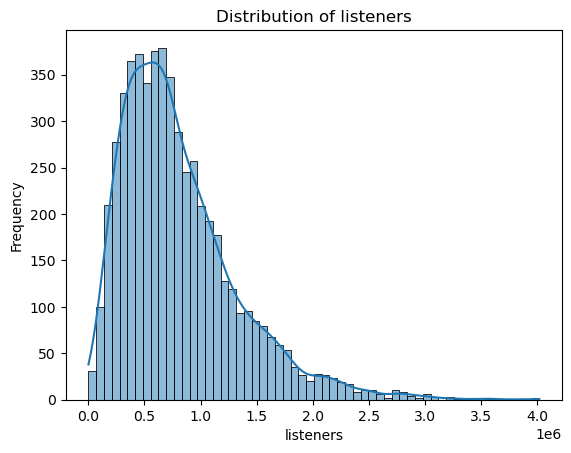

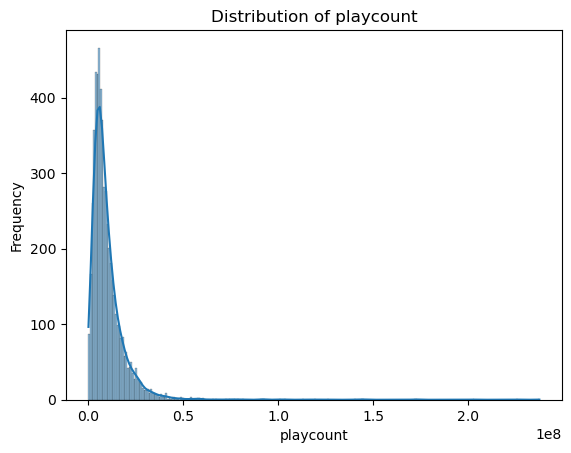

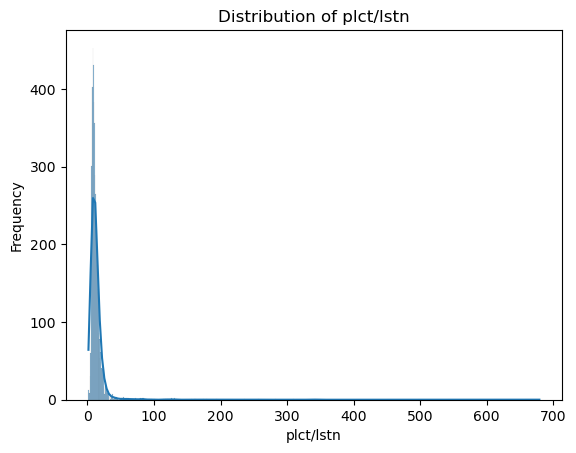

In [31]:
#Prevelant Skew 
numeric_cols = ['listeners', 'playcount', 'plct/lstn']

for col in numeric_cols:
    plt.figure()
    sns.histplot(df[col], kde=True)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.show()

In [55]:
for col in numeric_cols:
    print(f"Statistics for {col}:")
    print(f"Mean: {df[col].mean()}")
    print(f"Median: + {df[col].median()}")
    print(f"SD:  + {df[col].std()}")

Statistics for listeners:
Mean: 806743.2425715829
Median: + 692765.0
SD:  + 521958.8688471747
Statistics for playcount:
Mean: 10038582.388078516
Median: + 7389662.0
SD:  + 10904198.659750942
Statistics for plct/lstn:
Mean: 13.700019783920776
Median: + 10.482368617177444
SD:  + 21.984948421307074


In [59]:
exclude_cols = ['Unnamed: 0','artist','track','listeners','playcount','tags','plct/lstn']

categorical_cols = [col for col in df.columns if col not in exclude_cols]

for col in categorical_cols:
    print(f"Value counts for {col}:")
    print(df[col].value_counts())

Value counts for Disco:
Disco
0    5452
1     101
Name: count, dtype: int64
Value counts for Grunge:
Grunge
0    5460
1      93
Name: count, dtype: int64
Value counts for Hip-Hop:
Hip-Hop
0    4961
1     592
Name: count, dtype: int64
Value counts for House:
House
0    5449
1     104
Name: count, dtype: int64
Value counts for Korean:
Korean
0    5372
1     181
Name: count, dtype: int64
Value counts for Kpop:
Kpop
0    5332
1     221
Name: count, dtype: int64
Value counts for Love:
Love
0    5391
1     162
Name: count, dtype: int64
Value counts for Neo-Soul:
Neo-Soul
0    5428
1     125
Name: count, dtype: int64
Value counts for Nu Metal:
Nu Metal
0    5433
1     120
Name: count, dtype: int64
Value counts for Southern Hip Hop:
Southern Hip Hop
0    5457
1      96
Name: count, dtype: int64
Value counts for alternative:
alternative
0    4673
1     880
Name: count, dtype: int64
Value counts for alternative metal:
alternative metal
0    5413
1     140
Name: count, dtype: int64
Value counts f